In [1]:
import numpy as np
from pathlib import Path
from astropy.io import fits
import matplotlib.pyplot as plt
from astropy.wcs import WCS

In [2]:
cosmo_id = 1
realization_id = 0
field = 'GAMA09H'
z_tomo = 1

In [3]:
main_dir = Path('/lustre/work/gmarques/HSC_Y3_analysis_Gabriela')
mask = fits.getdata(main_dir / f'cosmo_varied/model{cosmo_id}/mask_{field}_z{z_tomo}.fits', 0)
wcs = WCS(fits.getheader(main_dir / f'cosmo_varied/model{cosmo_id}/mask_{field}_z{z_tomo}.fits', 0))

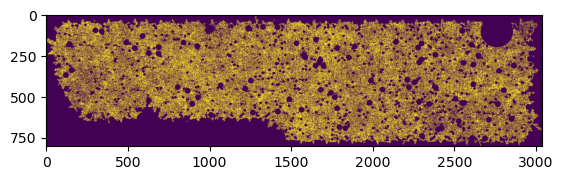

In [18]:
plt.imshow(mask)

In [4]:
kappa = fits.getdata(main_dir / f'cosmo_varied/model{cosmo_id}/E_{field}smoothed_z{z_tomo}_{realization_id}.fits', 0)

In [5]:
kappa

array([[-1.53701452e-02, -7.99142650e-03, -6.58904736e-03, ...,
        -3.25418022e-02, -3.37677470e-02, -3.46080422e-02],
       [-1.50802896e-02, -1.09830378e-02, -8.05873520e-03, ...,
        -2.84847000e-02, -2.86123090e-02, -2.60340932e-02],
       [-1.47855225e-02, -1.15591970e-02, -9.16940274e-03, ...,
        -2.52831842e-02, -2.45853755e-02, -2.34447762e-02],
       ...,
       [ 9.89822434e-03,  7.78619510e-03,  6.30590608e-03, ...,
        -1.21975391e-02, -1.56120245e-02, -2.00314417e-02],
       [ 8.55294470e-03,  4.77519764e-03,  3.70919501e-03, ...,
        -9.92987064e-03, -1.40299209e-02, -1.93618732e-02],
       [ 9.85364512e-04,  3.22478943e-04, -9.46275798e-05, ...,
        -7.10819642e-03, -9.75770664e-03, -1.85276194e-02]],
      shape=(803, 3040), dtype='>f8')

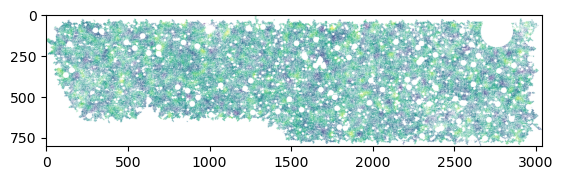

In [6]:
kappa_plot = np.ma.MaskedArray(kappa, mask=mask == 0)

cmap = plt.cm.viridis
cmap.set_bad(color='white')

plt.imshow(kappa_plot, cmap=cmap)

In [19]:
fid_id = 1403
kappa_fid = fits.getdata(main_dir / f'fiducial_maps/E_fid_{field}smoothed_z{z_tomo}_{fid_id}.fits', 0)

In [20]:
k = []
for i in range(1404):
    kappa_fid = fits.getdata(main_dir / f'fiducial_maps/E_fid_{field}smoothed_z{z_tomo}_{i}.fits', 0)
    k.append(kappa_fid)

In [26]:
k = np.array(k)

In [29]:
(k.nbytes) / (1024 * 1024 * 1024)  # Convert bytes to GB

25.535616874694824